In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
ieei = xr.open_dataset("/glade/work/wkamp/GEO/PRISM/PRISM/ohc_ieei_rebuild/b.e21.BW1850.f09_g17.CMIP6-piControl.001.iEEI.y1-100.nc")
ieei

<xarray.Dataset> Size: 38kB
Dimensions:            (time: 1200)
Coordinates:
  * time               (time) object 10kB 0001-01-01 00:00:00 ... 0100-12-01 ...
Data variables:
    EEI_global_mean    (time) float64 10kB ...
    iEEI_global_mean   (time) float64 10kB ...
    iEEI_total_joules  (time) float64 10kB ...
Attributes:
    case:             b.e21.BW1850.f09_g17.CMIP6-piControl.001
    asr_variable:     FSNT
    olr_variable:     FLNT
    ieei_start_time:  0001-01-01
    end_year:         100

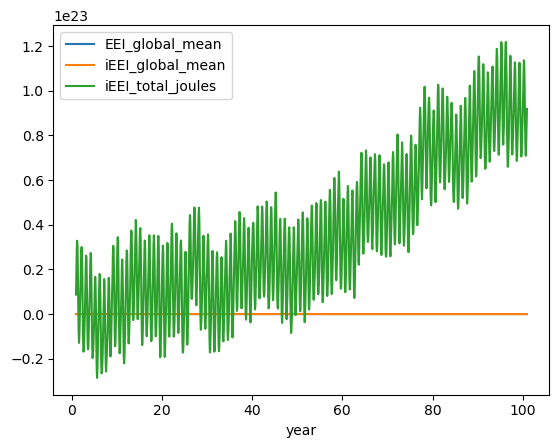

In [3]:
# matplotlib can't plot cftime.DatetimeNoLeap objects directly, and this run
# starts at year 1, which is out of pandas' Timestamp range (~1677-2262), so
# .to_datetimeindex() isn't an option either -- plot a plain decimal-year
# axis instead (noleap calendar: every year has exactly 365 days).
year_frac = ieei.time.dt.year + (ieei.time.dt.dayofyear - 1) / 365.0

for var in ieei.data_vars:
    plt.plot(year_frac, ieei[var], label=var)
plt.xlabel("year")
plt.legend()

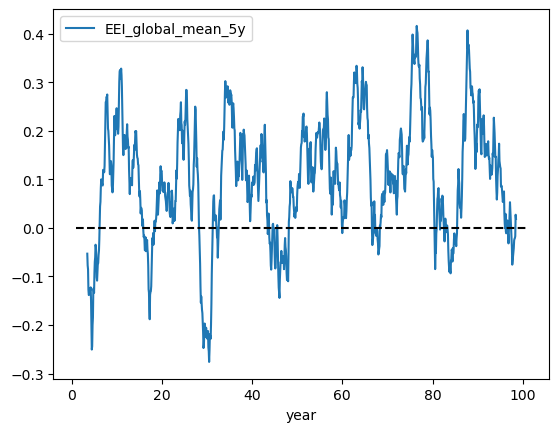

In [8]:
# 5y-mean smoothing
EEI_global_mean_5y = ieei.EEI_global_mean.rolling(time=60, center=True).mean()

# plt.plot(year_frac, ieei.EEI_global_mean, label="EEI_global_mean")
plt.plot(year_frac, EEI_global_mean_5y, label="EEI_global_mean_5y")
# plt.plot(year_frac, ieei.iEEI_global_mean, label="iEEI_global_mean")
plt.hlines(0, year_frac[0], year_frac[-1], color="k", linestyle="--")
plt.xlabel("year")
plt.legend()

In [ ]:
### workspace for testing things out below

In [2]:
ohc_path ='/glade/work/wkamp/GEO/PRISM/PRISM/ohc_ieei_rebuild/b.e21.BW1850.f09_g17.CMIP6-piControl.001.OHC.y1-100.nc'
ohc = xr.open_dataset(ohc_path)
ohc

<xarray.Dataset> Size: 2GB
Dimensions:          (nlat: 384, nlon: 320, time: 1200, ohc_depth: 4)
Coordinates:
    ULONG            (nlat, nlon) float64 983kB ...
    ULAT             (nlat, nlon) float64 983kB ...
    TLONG            (nlat, nlon) float64 983kB ...
    TLAT             (nlat, nlon) float64 983kB ...
  * time             (time) object 10kB 0001-01-01 00:00:00 ... 0100-12-01 00...
  * ohc_depth        (ohc_depth) int64 32B -1 300 700 2000
Dimensions without coordinates: nlat, nlon
Data variables:
    OHC              (ohc_depth, time, nlat, nlon) float32 2GB ...
    OHC_global_mean  (ohc_depth, time) float64 38kB ...
Attributes:
    global_area_m2:  504921015096543.6
    ocean_area_m2:   360511672426927.94
    rho_kg_m3:       1026.026026026026
    cp_j_kg_k:       3996.0
    case:            b.e21.BW1850.f09_g17.CMIP6-piControl.001
    source_files:    /glade/campaign/collections/cmip/CMIP6/timeseries-cmip6/...
    start_year:      1
    end_year:        100

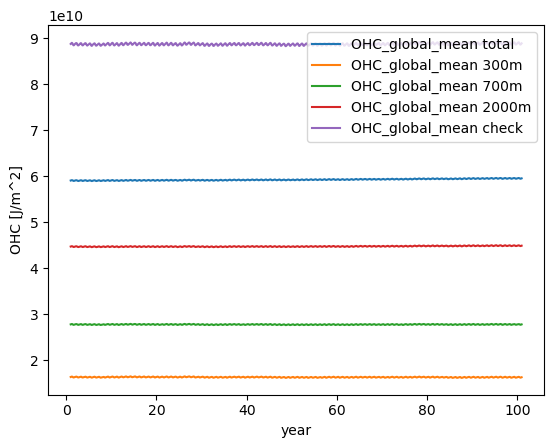

In [15]:
year_frac = ohc.time.dt.year + (ohc.time.dt.dayofyear - 1) / 365.0
ohc['ohc_check'] = (ohc.OHC_global_mean.sel(ohc_depth=300) + ohc.OHC_global_mean.sel(ohc_depth=700) + ohc.OHC_global_mean.sel(ohc_depth=2000))

plt.plot(year_frac, ohc.OHC_global_mean.sel(ohc_depth=-1), label="OHC_global_mean total")
plt.plot(year_frac, ohc.OHC_global_mean.sel(ohc_depth=300), label="OHC_global_mean 300m")
plt.plot(year_frac, ohc.OHC_global_mean.sel(ohc_depth=700), label="OHC_global_mean 700m")
plt.plot(year_frac, ohc.OHC_global_mean.sel(ohc_depth=2000), label="OHC_global_mean 2000m")
plt.plot(year_frac, ohc.ohc_check, label="OHC_global_mean check")

plt.xlabel("year")
plt.ylabel("OHC [J/m^2]")
plt.legend()

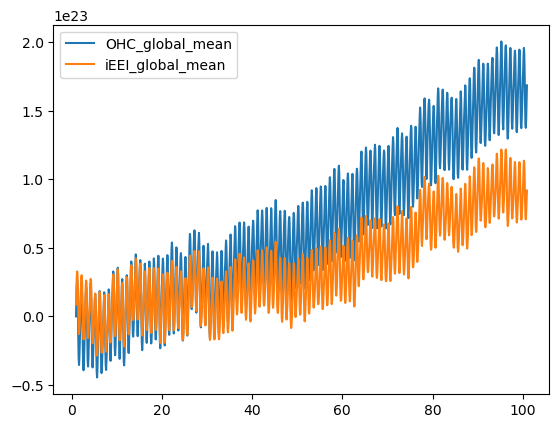

In [25]:
t0 = ohc.OHC_global_mean.sel(ohc_depth=-1).isel(time=0)
ohc['tot'] = (ohc.OHC_global_mean - ohc.OHC_global_mean.isel(time=0)) * ohc.attrs["ocean_area_m2"]



plt.plot(year_frac, ohc.tot.sel(ohc_depth=-1), label="OHC_global_mean")
plt.plot(year_frac, ieei.iEEI_total_joules, label="iEEI_global_mean")

plt.legend()